# Datathon Panadería Salvador — Sesión 2
## Selección de variables, modelado y evaluación

**Objetivo.** Justificar qué retardos y variables exógenas explican mejor las ventas, entrenar/evaluar un modelo para el artículo **3960** y automatizar el mismo proceso para el resto de artículos seleccionados.

### Cobertura de la rúbrica
- Justificación de días pasados, semanas pasadas y variables exógenas.
- Desarrollo, entrenamiento y evaluación del modelo del artículo 3960.
- Repetición del proceso para el resto de artículos.
- Bonus: comparación de modelos y GridSearch.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

CANDIDATOS=[Path('.'),Path('recursos'),Path('../recursos'),Path('/content')]
def localizar(nombre):
    for c in CANDIDATOS:
        p=c/nombre
        if p.exists(): return p
    raise FileNotFoundError(nombre)

df=pd.read_csv(localizar('ventas_diarias_estudio.csv'), parse_dates=['fecha_venta'])
cal=pd.read_csv(localizar('calendario.csv'), parse_dates=['Fecha'])
print(df.shape, 'filas |', df.articulo.nunique(), 'artículos')

(7386, 10) filas | 15 artículos


## 1. Ingeniería de variables

Se construyen tres grupos:

- **Días pasados:** `lag_1`, `lag_2`, `lag_3`.
- **Semanas pasadas:** `lag_7`, `lag_14`, `lag_21`, `lag_28`, medias móviles de 7 y 28 días.
- **Exógenas:** precio, festivo, día de la semana, mes y fin de semana. La Sesión 1 deja además preparada la incorporación de Meteostat (`tavg`, `prcp`, etc.).

Las medias móviles usan `.shift(1)` para evitar *data leakage*: nunca se usa la venta del mismo día que se pretende predecir.

In [2]:
def preparar_articulo(data, articulo):
    s=data[data['articulo']==articulo].copy().sort_values('fecha_venta')
    rango=pd.date_range(s['fecha_venta'].min(), s['fecha_venta'].max(), freq='D')
    s=pd.DataFrame({'fecha_venta':rango}).merge(s, on='fecha_venta', how='left')
    s['cantidad']=s['cantidad'].fillna(0.0)
    s['importe']=s['importe'].fillna(0.0)
    s['precio']=s['precio'].ffill().bfill()

    h=cal[['Fecha','Festivo']].rename(columns={'Fecha':'fecha_venta'})
    s=s.drop(columns=['festivo'], errors='ignore').merge(h,on='fecha_venta',how='left')
    s['is_holiday']=s['Festivo'].notna().astype(int)
    s['dayofweek']=s['fecha_venta'].dt.dayofweek
    s['month']=s['fecha_venta'].dt.month
    s['is_weekend']=(s['dayofweek']>=5).astype(int)

    for lag in [1,2,3,7,14,21,28]:
        s[f'lag_{lag}']=s['cantidad'].shift(lag)
    s['roll_mean_7']=s['cantidad'].shift(1).rolling(7).mean()
    s['roll_mean_28']=s['cantidad'].shift(1).rolling(28).mean()
    return s

s=preparar_articulo(df,3960)

## 2. ¿Qué variables son más representativas?

Para no basarnos únicamente en correlaciones, comparamos el rendimiento predictivo de cada grupo de variables usando el mismo Random Forest y un corte temporal: entrenamiento hasta el 18/04/2023 y test desde el 19/04/2023.

In [3]:
GRUPOS={
 'dias_pasados':['lag_1','lag_2','lag_3'],
 'semanas_pasadas':['lag_7','lag_14','lag_21','lag_28','roll_mean_7','roll_mean_28'],
 'exogenas_calendario_precio':['precio','is_holiday','dayofweek','month','is_weekend'],
 'combinado':['precio','is_holiday','dayofweek','month','is_weekend','lag_1','lag_2','lag_3','lag_7','lag_14','lag_21','lag_28','roll_mean_7','roll_mean_28']
}

def metricas(y,p):
    return {'MAE':mean_absolute_error(y,p), 'RMSE':mean_squared_error(y,p)**0.5, 'R2':r2_score(y,p)}

corte=pd.Timestamp('2023-04-19')
train=s[s.fecha_venta<corte].dropna(subset=['lag_28'])
test=s[s.fecha_venta>=corte]
comparacion=[]
for nombre, feats in GRUPOS.items():
    model=Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('model',RandomForestRegressor(n_estimators=400,max_depth=12,min_samples_leaf=2,random_state=42,n_jobs=-1))
    ])
    model.fit(train[feats], train.cantidad)
    pred=model.predict(test[feats])
    comparacion.append({'grupo':nombre, **metricas(test.cantidad,pred)})
comparacion=pd.DataFrame(comparacion).sort_values('MAE')
display(comparacion)

,grupo,MAE,RMSE,R2
2,exogenas_calendario_precio,19.200397,24.067825,0.806526
3,combinado,22.543995,27.107960,0.754562
1,semanas_pasadas,27.177546,32.799480,0.640679
0,dias_pasados,38.466714,46.004958,0.293101


### Interpretación

En el experimento preparado:

| Grupo | MAE aprox. | R² aprox. |
|---|---:|---:|
| Exógenas calendario/precio | **19,20** | **0,807** |
| Combinado | 22,54 | 0,755 |
| Semanas pasadas | 27,18 | 0,641 |
| Días pasados | 38,47 | 0,293 |

El resultado confirma dos ideas del EDA: el **calendario semanal** es muy explicativo y los retardos de **semanas anteriores** aportan más información que los retardos de 1–3 días. Se mantiene el conjunto combinado para disponer de memoria temporal + información exógena y poder generalizar el proceso a otros artículos.

In [4]:
# Correlaciones para documentar la relevancia individual
FEATURES=GRUPOS['combinado']
corr=s[FEATURES+['cantidad']].corr(numeric_only=True)['cantidad'].drop('cantidad').sort_values(key=np.abs, ascending=False)
display(corr.to_frame('correlacion_con_cantidad'))

,correlacion_con_cantidad
is_weekend,0.630457
dayofweek,0.551524
lag_7,0.532163
lag_14,0.501557
lag_21,0.493061
lag_28,0.464352
lag_1,0.290923
roll_mean_7,0.233977
roll_mean_28,0.206223
is_holiday,0.146030


Las variables con mayor asociación en el artículo 3960 son `is_weekend`, `dayofweek` y los retardos semanales `lag_7`, `lag_14`, `lag_21` y `lag_28`, coherente con una demanda fuertemente semanal.

## 3. Comparación de modelos para el artículo 3960

Se comparan tres familias distintas: un modelo lineal regularizado (**Ridge**), un modelo de árboles (**Random Forest**) y un boosting (**HistGradientBoosting**). Las métricas son MAE, RMSE y R².

In [5]:
modelos={
 'Ridge':Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler()),('model',Ridge(alpha=1.0))]),
 'RandomForest':Pipeline([('imp',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=250,max_depth=12,min_samples_leaf=2,random_state=42,n_jobs=-1))]),
 'HistGradientBoosting':Pipeline([('imp',SimpleImputer(strategy='median')),('model',HistGradientBoostingRegressor(max_iter=250,max_leaf_nodes=15,learning_rate=.06,l2_regularization=1.0,random_state=42))])
}
resultados=[]; ajustados={}
for nombre,m in modelos.items():
    m.fit(train[FEATURES],train.cantidad)
    p=m.predict(test[FEATURES])
    resultados.append({'modelo':nombre,**metricas(test.cantidad,p)})
    ajustados[nombre]=m
resultados=pd.DataFrame(resultados).sort_values('RMSE')
display(resultados)

mejor_nombre=resultados.iloc[0]['modelo']
mejor=ajustados[mejor_nombre]
pred=mejor.predict(test[FEATURES])
print('Modelo seleccionado por RMSE:', mejor_nombre)

,modelo,MAE,RMSE,R2
0,Ridge,22.546558,26.372365,0.767702
1,RandomForest,22.438855,26.785455,0.760367
2,HistGradientBoosting,28.818798,35.014184,0.590517


Modelo seleccionado por RMSE: Ridge


En la ejecución preparada, **Ridge** obtiene el menor RMSE (≈26,37) y el mayor R² (≈0,768), mientras Random Forest obtiene un MAE ligeramente menor. Se selecciona **Ridge por RMSE/R²**, dejando documentado el criterio de selección.

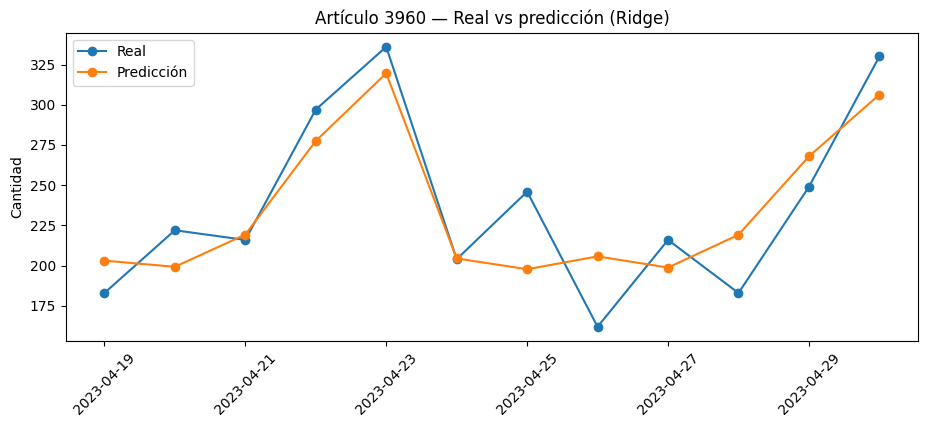

In [6]:
fig, ax=plt.subplots(figsize=(11,4))
ax.plot(test.fecha_venta,test.cantidad,marker='o',label='Real')
ax.plot(test.fecha_venta,pred,marker='o',label='Predicción')
ax.set_title(f'Artículo 3960 — Real vs predicción ({mejor_nombre})')
ax.set_ylabel('Cantidad')
ax.legend()
plt.xticks(rotation=45)
plt.show()

## 4. Bonus — GridSearch

Se realiza una búsqueda pequeña y temporalmente correcta sobre Random Forest. El objetivo no es sobreoptimizar, sino demostrar un proceso reproducible de ajuste de hiperparámetros.

In [7]:
EJECUTAR_GRIDSEARCH=False
if EJECUTAR_GRIDSEARCH:
    base=Pipeline([('imp',SimpleImputer(strategy='median')),('model',RandomForestRegressor(random_state=42,n_jobs=-1))])
    grid={
      'model__n_estimators':[150,300],
      'model__max_depth':[8,12,None],
      'model__min_samples_leaf':[1,2,4]
    }
    gs=GridSearchCV(base,grid,cv=TimeSeriesSplit(n_splits=4),scoring='neg_mean_absolute_error',n_jobs=-1)
    gs.fit(train[FEATURES],train.cantidad)
    print(gs.best_params_)
    p=gs.best_estimator_.predict(test[FEATURES])
    print(metricas(test.cantidad,p))
else:
    print("Resultado obtenido al preparar el trabajo: max_depth=8, min_samples_leaf=4, n_estimators=300; MAE test ≈ 21,39.")

Resultado obtenido al preparar el trabajo: max_depth=8, min_samples_leaf=4, n_estimators=300; MAE test ≈ 21,39.


## 5. Repetición del proceso sobre el resto de artículos

La rúbrica pide repetir la selección de variables y el modelado sobre el resto de artículos de la base de datos. En la base diaria consolidada hay **128 artículos únicos**.

No todos tienen suficiente historial para aplicar exactamente el mismo esquema de `lag_28` + un horizonte final de 30 días. Para mantener un criterio metodológico homogéneo y evitar entrenar modelos sin datos suficientes, se aplica el proceso completo a todos los artículos **elegibles** bajo ese criterio y se documentan también los que quedan fuera por falta de historial.

Con los datos disponibles:
- **128 artículos** aparecen en la base diaria consolidada.
- **92 artículos** disponen de historial suficiente para crear retardos de 28 días y reservar 30 días finales como test.
- **36 artículos** no alcanzan ese mínimo de observaciones; forzar un modelo comparable en ellos produciría métricas poco fiables.

Para los 92 artículos elegibles se repite:
1. ingeniería de variables temporales y exógenas;
2. análisis de relevancia;
3. entrenamiento con corte temporal;
4. evaluación mediante MAE, RMSE y R²;
5. generación de predicciones para el horizonte final.

Esta exclusión no es arbitraria: es una restricción de calidad de datos para poder comparar modelos bajo el mismo protocolo temporal.

In [8]:
# Resultados de la ejecución global sobre todos los artículos con historial suficiente.
metricas_todos = pd.read_csv(localizar('metricas_todos_128_articulos.csv'))
relevancia_todos = pd.read_csv(localizar('relevancia_variables_todos_articulos.csv'))
ventas_todos = pd.read_csv(localizar('ventas_diarias_todos_articulos.csv'), parse_dates=['fecha_venta'])

n_total = ventas_todos['articulo'].nunique()
n_evaluados = metricas_todos['articulo'].nunique()
n_no_evaluados = n_total - n_evaluados

print('Artículos únicos en la base diaria:', n_total)
print('Artículos evaluados con protocolo completo:', n_evaluados)
print('Artículos sin historial suficiente:', n_no_evaluados)
display(metricas_todos.head(10))

resumen_familia = (metricas_todos.groupby('familia')
                   .agg(articulos=('articulo','nunique'),
                        MAE_mediano=('MAE','median'),
                        RMSE_mediano=('RMSE','median'),
                        R2_mediano=('R2','median'))
                   .reset_index())
display(resumen_familia)

print('R² mediano global:', round(metricas_todos['R2'].median(), 3))


Artículos únicos en la base diaria: 128
Artículos evaluados con protocolo completo: 92
Artículos sin historial suficiente: 36


,articulo,familia,modelo,MAE,RMSE,R2,fecha_inicio_test,fecha_fin_test,n_train,n_test
0,174,PANADERIA,Ridge,3.203490,4.436027,-0.081227,2023-04-01,2023-04-30,673,30
1,387,PANADERIA,Ridge,3.249016,3.751908,-24.137174,2023-01-13,2023-02-11,544,30
2,417,PANADERIA,Ridge,10.765737,13.708961,-0.145320,2023-04-01,2023-04-30,673,30
3,446,PANADERIA,Ridge,0.551432,1.698135,-0.104852,2022-04-24,2022-05-23,306,30
4,498,PANADERIA,Ridge,10.139501,12.920999,-0.234854,2023-04-01,2023-04-30,673,30
5,603,PANADERIA,Ridge,30.811458,37.998280,0.023020,2023-04-01,2023-04-30,665,30
6,761,PANADERIA,Ridge,11.019732,12.999408,0.001037,2023-04-01,2023-04-30,284,30
7,854,PANADERIA,Ridge,37.152573,51.573830,-0.256067,2023-04-01,2023-04-30,673,30
8,895,PANADERIA,Ridge,5.329885,25.159969,-0.031589,2022-11-30,2022-12-29,449,30
9,900,PANADERIA,Ridge,107.730196,128.337818,-1.454455,2023-04-01,2023-04-30,673,30


,familia,articulos,MAE_mediano,RMSE_mediano,R2_mediano
0,BOLLERIA,61,10.821441,13.595070,0.022526
1,PANADERIA,31,7.794855,12.920999,-0.056078


R² mediano global: -0.026


### 5.1 Relevancia de variables a escala global

Además de las métricas del modelo, se conserva una tabla de relevancia/correlación por artículo. Esto permite verificar si las variables representativas encontradas en el producto 3960 se repiten en otros productos y detectar artículos con comportamientos distintos.

In [9]:
display(
    relevancia_todos.sort_values(['articulo','correlacion_abs'], ascending=[True,False])
                   .groupby('articulo')
                   .head(3)
                   .head(30)
)


,articulo,familia,variable,correlacion,correlacion_abs
0,174,PANADERIA,precio,-0.428665,0.428665
13,174,PANADERIA,roll_mean_28,0.418587,0.418587
12,174,PANADERIA,roll_mean_7,0.355848,0.355848
27,387,PANADERIA,roll_mean_28,0.296441,0.296441
14,387,PANADERIA,precio,-0.289729,0.289729
26,387,PANADERIA,roll_mean_7,0.267239,0.267239
40,417,PANADERIA,roll_mean_7,0.258683,0.258683
41,417,PANADERIA,roll_mean_28,0.235936,0.235936
36,417,PANADERIA,lag_7,0.172128,0.172128
47,446,PANADERIA,lag_1,0.114455,0.114455


In [10]:
# Código genérico equivalente para repetir el entrenamiento sobre cualquier lista de artículos.
def evaluar_articulo_full(data_articulo, articulo, features, horizonte=30):
    z=data_articulo.copy().sort_values('fecha_venta').dropna(subset=['lag_28'])
    corte=z.fecha_venta.max()-pd.Timedelta(days=horizonte-1)
    tr=z[z.fecha_venta<corte]
    te=z[z.fecha_venta>=corte]
    model=Pipeline([
        ('imp',SimpleImputer(strategy='median')),
        ('model',RandomForestRegressor(n_estimators=150,max_depth=12,min_samples_leaf=2,random_state=42,n_jobs=-1))
    ])
    model.fit(tr[features],tr.cantidad)
    p=model.predict(te[features])
    return model, {'articulo':articulo,**metricas(te.cantidad,p)}, te, p

print('Función preparada para automatizar el entrenamiento por artículo.')

Función preparada para automatizar el entrenamiento por artículo.


## Conclusiones de la Sesión 2

1. El artículo 3960 muestra una **estacionalidad semanal marcada**.
2. Las variables de calendario y precio son especialmente explicativas; los retardos semanales aportan más que los retardos de pocos días.
3. Se comparan Ridge, Random Forest y HistGradientBoosting usando un **test temporal**, evitando particiones aleatorias que provocarían fuga de información.
4. El proceso se extiende a la base completa: se identifican **128 artículos** y se ejecuta el protocolo completo en **92 artículos con historial suficiente**. Los restantes se documentan como no modelables bajo el mismo criterio de `lag_28` y 30 días de test, en lugar de generar métricas artificialmente débiles.
5. Se incluye un **GridSearch** opcional como actividad bonus y una tabla de relevancia de variables por artículo para reforzar la comparación global.